# Lab01: So sánh ba cấu hình MLP
SmallMLP/MainMLP dùng pixel; MainMLP_FE dùng pixel + 10 feature. Best checkpoint theo validation accuracy, test chỉ đánh giá sau huấn luyện. Không dùng metric lịch sử như kết quả mới.

## Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai đoạn (Phase) | Nội dung chi tiết (Core Description) | Module triển khai | Sản phẩm đầu ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Data Contract** | Chọn prepared.npz từ notebook 01; cùng split/seed; tự chọn CPU hoặc CUDA. | `src.utils.helpers`<br>`src.training.comparison` | `config.json`<br>`environment_snapshot.json`<br>`data SHA256` |
| **2** | **Model & Sanity Overfit** | Khởi tạo SmallMLP 784-128-10, MainMLP 784-256-128-10 và MainMLP_FE 794-256-128-10; sanity rồi reset model/seed. | `src.models.mlp`<br>`src.training.trainer` | `sanity.json`<br>`cấu hình từng model` |
| **3** | **Training** | Train ba cấu hình với Adam và CosineAnnealingLR; lưu history mỗi epoch, chọn best bằng validation. | `src.training.comparison`<br>`src.training.trainer` | `best.pt`<br>`history.json`<br>`history.csv`<br>`learning_curves.png` |
| **4** | **Test Evaluation** | Tải best checkpoint, đánh giá test; lưu xác suất, nhãn, metric và class report. | `src.training.comparison` | `test_predictions.npz`<br>`metrics.json`<br>`classification_report.json`<br>`classification_report.csv` |
| **5** | **Model Comparison** | So sánh Accuracy/Macro F1, validation curves, chi phí; confusion matrix và cùng 16 ảnh dự đoán. Không có F1 heatmap. | `src.utils.comparison_plots` | `comparison.csv`<br>`test_scores.png`<br>`validation_comparison.png`<br>`cost.png`<br>`confusion_comparison.png`<br>`*_prediction_grid.png` |
| **6** | **ROC & Precision–Recall OvR** | Mỗi model một ảnh hai panel ROC/PR, mỗi panel có 10 đường one-vs-rest; lưu tọa độ và điểm số. | `src.utils.comparison_plots` | `*_ovr_curves.png (3 ảnh)`<br>`*_roc_*.csv`<br>`*_pr_*.csv`<br>`ovr_scores_by_class.csv` |
| **7** | **Fixed-LR Optimizers** | Giữ MainMLP pixel; SGD/RMSprop/Adam cùng lr=0.001; so sánh trên validation. | `src.training.tuning.run_fixed_lr` | `summary.csv`<br>`fixed_lr_curves.png`<br>`candidates/*/history.csv`<br>`candidates/*/best.pt` |
| **8** | **Hyperparameter Search** | Ba study độc lập, 10 trial/optimizer; LR, weight decay và momentum SGD; MedianPruner. Lượt hiện tại có 10 startup trials nên chưa vào pha TPE thích nghi. | `src.training.tuning.run_tuning` | `studies.sqlite3`<br>`*_trials.csv`<br>`all_trials.csv`<br>`best_configs.json/csv`<br>`tuning_progress.png`<br>`trials/*` |
| **9** | **Refit & Final Evaluation** | Refit best trong study theo validation rồi đánh giá test; so fixed-vs-tuned, không mặc định tuning tốt hơn baseline. | `src.training.tuning.refit_winner`<br>`summarize_optimizer_runs` | `refit_run.json`<br>`fixed_vs_tuned.csv/png`<br>`final_metrics.json`<br>`final_ovr_curves.png`<br>`final_confusion_matrix.png` |
| **10** | **Artifact Review & Tracking** | Xem kết quả đã lưu mà không train lại; ghi log, trạng thái, môi trường và checksum theo run. | `src.utils.runs`<br>`notebook 02` | `console.log`<br>`status.json`<br>`manifest.json`<br>`notebook đọc lại đã thực thi` |

**Quy ước đường dẫn:** output trong bảng nằm tương đối dưới `outputs/runs/<run_id>/` của giai đoạn tương ứng. Mỗi lần chạy tạo thư mục riêng; không dùng đường dẫn output cố định của notebook lịch sử. Roadmap mô tả luồng triển khai, không phải tuyên bố mọi run đều đã hoàn thành.


In [ ]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
LAB = next((p for p in candidates if (p / 'src/models/mlp.py').is_file()), None)
if LAB is None:
    LAB = next((p / 'labs/lab01' for p in candidates if (p / 'labs/lab01/src/models/mlp.py').is_file()), None)
if LAB is None:
    raise RuntimeError('Set working directory to the repository or lab01 folder; on Kaggle mount/copy the lab source first.')
sys.path.insert(0, str(LAB))
from src.utils.helpers import OUTPUTS_DIR
from IPython.display import display, Image


## 1. Chọn artifact dữ liệu
Điền đường dẫn từ notebook 01; không tự chọn run mới nhất để tránh dùng nhầm dữ liệu.

In [ ]:
DATA_PATH = OUTPUTS_DIR / 'runs/20261022T122157Z_preparation_dcaece7b/prepared.npz'
assert DATA_PATH.is_file(), 'Run notebook 01 and set DATA_PATH first'
from src.training.comparison import CONFIGS, run_model
print(CONFIGS)


## 2. Huấn luyện
Mỗi cell tạo một run riêng, kiểm tra one-batch overfit rồi khởi tạo lại. Config, log, sanity, history từng epoch, best checkpoint, prediction probabilities và metrics được lưu. Full training chạy được trên local CPU/CUDA hoặc Kaggle. CUDA được chọn nếu có; CPU được dùng nếu không có. Cùng seed, batch, epochs, Adam và CosineAnnealingLR.

### SmallMLP

In [ ]:
SmallMLP_RUN = run_model(DATA_PATH, 'SmallMLP', epochs=10, seed=42)
display(Image(filename=str(SmallMLP_RUN / 'learning_curves.png')))

### MainMLP

In [ ]:
MainMLP_RUN = run_model(DATA_PATH, 'MainMLP', epochs=10, seed=42)
display(Image(filename=str(MainMLP_RUN / 'learning_curves.png')))

### MainMLP_FE

In [ ]:
MainMLP_FE_RUN = run_model(DATA_PATH, 'MainMLP_FE', epochs=10, seed=42)
display(Image(filename=str(MainMLP_FE_RUN / 'learning_curves.png')))

## 3. Tổng hợp và visualizations
So sánh dung lượng Small/Main và tác động FE Main/Main_FE. Accuracy, Macro F1, normalized confusion matrices, ROC và PR one-vs-rest (3 ảnh ghép, mỗi model 1 ảnh), learning curves, prediction grids chung 16 ảnh và chi phí. Không có biểu đồ cột TPR/FPR. Đường cong được lưu cả tọa độ CSV. AP và diện tích PR hình thang không được đánh đồng.

In [ ]:
from src.utils.comparison_plots import build_comparison
COMPARISON_RUN = build_comparison([SmallMLP_RUN, MainMLP_RUN, MainMLP_FE_RUN])

In [ ]:
import pandas as pd
display(pd.read_csv(COMPARISON_RUN / 'comparison.csv'))
# Three figures only: each model has ROC OvR and PR OvR panels.
for name in ('SmallMLP', 'MainMLP', 'MainMLP_FE'):
    display(Image(filename=str(COMPARISON_RUN / f'{name}_ovr_curves.png')))
print('Other comparison figures and numerical tables are saved at:', COMPARISON_RUN)


### Confusion matrices của ba model
Hàng là nhãn thật, cột là nhãn dự đoán; mỗi hàng chuẩn hóa về 1 để so sánh recall theo lớp. Cả ba dùng cùng thang màu. Bảng số lượng và tỷ lệ đầy đủ nằm trong CSV artifact.

In [ ]:
display(Image(filename=str(COMPARISON_RUN / 'confusion_comparison.png')))


## 4. Optimizer: thực nghiệm riêng
Notebook lịch sử chứa fixed-LR/Optuna. Không gộp optimizer vào ba cấu hình chính. Chỉ sử dụng study Optuna thật có log; chưa chạy study mới thì chưa có kết quả mới.

## 5. Ghi nhận kết quả
Sau run, cập nhật walkthrough bằng run_id, cấu hình, bảng so sánh, diễn giải hình và liên kết artifact. Chưa có run thì không điền metric giả. Nhật ký sửa đổi nội bộ không thuộc báo cáo PDF.

## 4. Optimizer cùng learning rate
Cố định MainMLP pixel, batch=128, seed=42, Adam/RMSprop/SGD momentum=0.9 cùng lr=0.001 và weight_decay=0. Không đánh giá test trong giai đoạn này. Mỗi candidate có run riêng và history/checkpoint. CPU/CUDA/Kaggle đều được hỗ trợ.

In [ ]:
from src.training.tuning import run_fixed_lr, run_tuning, refit_winner
EPOCHS = 10
TRIALS_PER_OPTIMIZER = 10
SEED = 42
BATCH_SIZE = 128
FIXED_LR_RUN = run_fixed_lr(DATA_PATH, epochs=EPOCHS, seed=SEED, batch_size=BATCH_SIZE)
display(pd.read_csv(FIXED_LR_RUN / 'summary.csv'))
display(Image(filename=str(FIXED_LR_RUN / 'fixed_lr_curves.png')))


## 5. Hyperparameter tuning: ngân sách bằng nhau
Ba study độc lập, mỗi optimizer 10 trial, tối đa 10 epoch/trial. Tune LR/weight decay, SGD tune thêm momentum. MedianPruner có thể dừng trial, vì vậy cùng ngân sách tối đa không đồng nghĩa cùng thời gian tính toán. Objective chỉ dùng validation accuracy; không truy cập nhãn test để chọn config. SQLite, trial CSV, config, stdout/stderr, history và weights best được lưu. Nếu thiếu Optuna, cài dependencies trước khi chạy; không có fallback metric giả.

In [ ]:
TUNING_RUN = run_tuning(DATA_PATH, trials_per_optimizer=TRIALS_PER_OPTIMIZER,
                        epochs=EPOCHS, seed=SEED, batch_size=BATCH_SIZE)
display(pd.read_csv(TUNING_RUN / 'best_configs.csv'))
display(Image(filename=str(TUNING_RUN / 'tuning_progress.png')))


## 6. Refit cấu hình thắng và đánh giá test
Chọn config có best validation accuracy cao nhất trong ba study, giữ nguyên epochs/seed/batch. Refit từ đầu, chọn checkpoint theo validation rồi đánh giá test. Không lấy kết quả tuned này để kết luận kiến trúc tốt hơn hai model chưa tune. Chỉ chạy cell này khi đã chốt cấu hình; chạy lại tạo refit run mới.

In [ ]:
FINAL_RUN = refit_winner(DATA_PATH, TUNING_RUN, epochs=EPOCHS, seed=SEED, batch_size=BATCH_SIZE)
import json
print(json.loads((FINAL_RUN / 'metrics.json').read_text()))
display(Image(filename=str(FINAL_RUN / 'learning_curves.png')))


## 7. So sánh fixed LR và tuned, kết quả cuối
Bảng validation so sánh best của từng optimizer. Thời gian tuned là tổng ngân sách các trial, không so ngang với một lượt fixed. Hiển thị hình chọn lọc và confusion matrix; CSV đầy đủ vẫn lưu trong artifact.

In [ ]:
from src.training.tuning import summarize_optimizer_runs
OPTIMIZER_RESULTS = summarize_optimizer_runs(FIXED_LR_RUN, TUNING_RUN, FINAL_RUN)
display(pd.read_csv(OPTIMIZER_RESULTS / 'fixed_vs_tuned.csv'))
display(Image(filename=str(OPTIMIZER_RESULTS / 'fixed_vs_tuned.png')))
display(Image(filename=str(OPTIMIZER_RESULTS / 'final_ovr_curves.png')))

display(Image(filename=str(OPTIMIZER_RESULTS / 'final_confusion_matrix.png')))


## 8. Đọc lại lượt optimizer đã hoàn thành (không train lại)
Đây là lựa chọn xem kết quả đã lưu thay cho việc chạy các cell huấn luyện optimizer ở trên. Lượt local CPU seed 42, 10 trial/optimizer đã hoàn thành; 16 trial COMPLETE và 14 PRUNED. Hiển thị chọn lọc ba ảnh, không quét toàn bộ thư mục. Best trong study không mặc định tốt hơn cấu hình fixed LR.

,optimizer,best_val_acc_fixed,seconds_fixed,best_val_acc_tuned,seconds_tuned
0,SGD,85.083333,10.368774,90.800000,84.527603
1,RMSprop,90.733333,12.454700,90.566667,115.180993
2,Adam,90.933333,14.972536,90.850000,104.964151


,optimizer,lr,weight_decay,momentum,best_val_acc,completed,pruned
0,SGD,0.026070,1.267426e-07,0.945486,90.800000,5,5
1,RMSprop,0.001593,3.470267e-04,NaN,90.566667,6,4
2,Adam,0.001593,3.470267e-04,NaN,90.850000,5,5


Test metrics of the validation-selected best configuration within tuning studies:
{'name': 'MainMLP', 'seed': 42, 'accuracy': 0.8914, 'macro_f1': 0.891219120478717, 'precision': 0.8912615745916137, 'recall': 0.8914, 'loss': 0.30367913842201233, 'train_seconds': 14.46218570000201, 'parameters': 235146, 'best_epoch': 10}


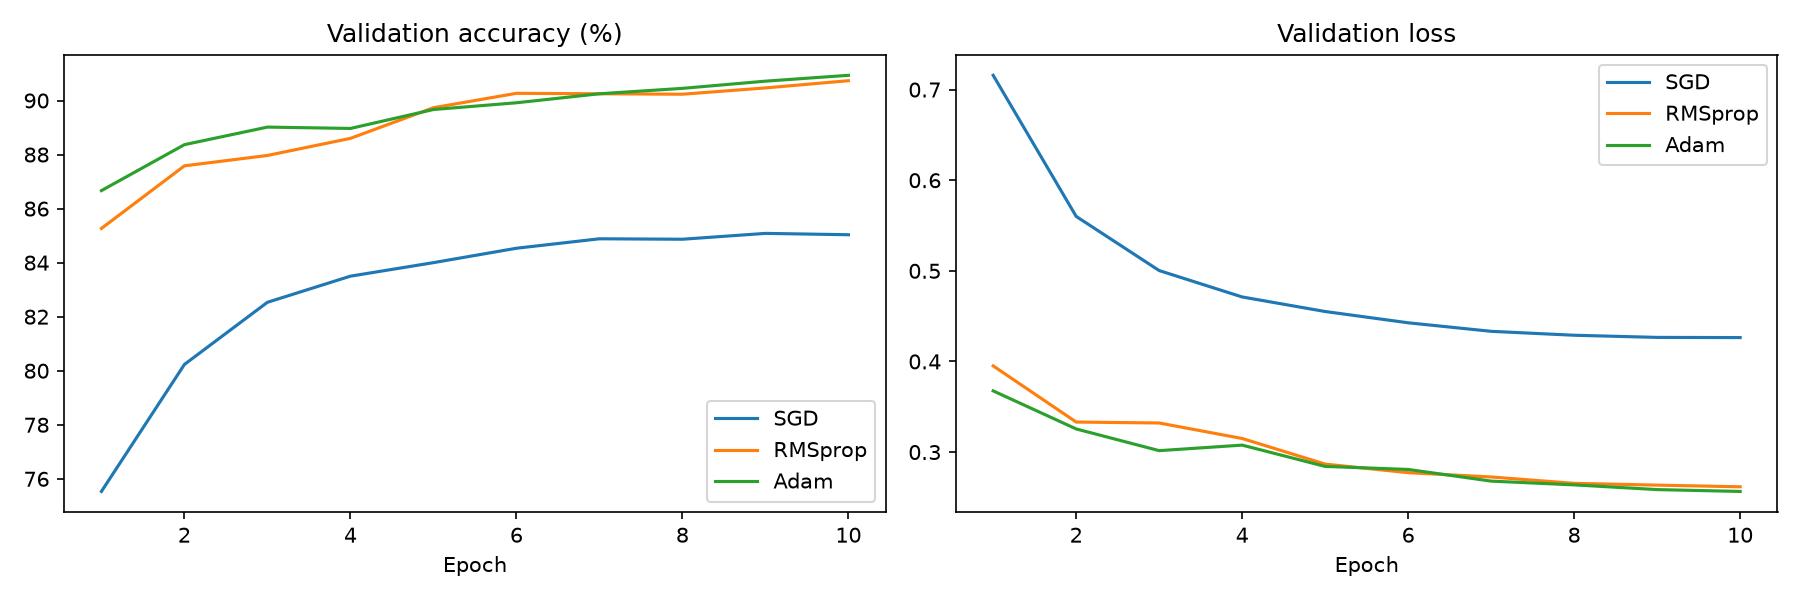

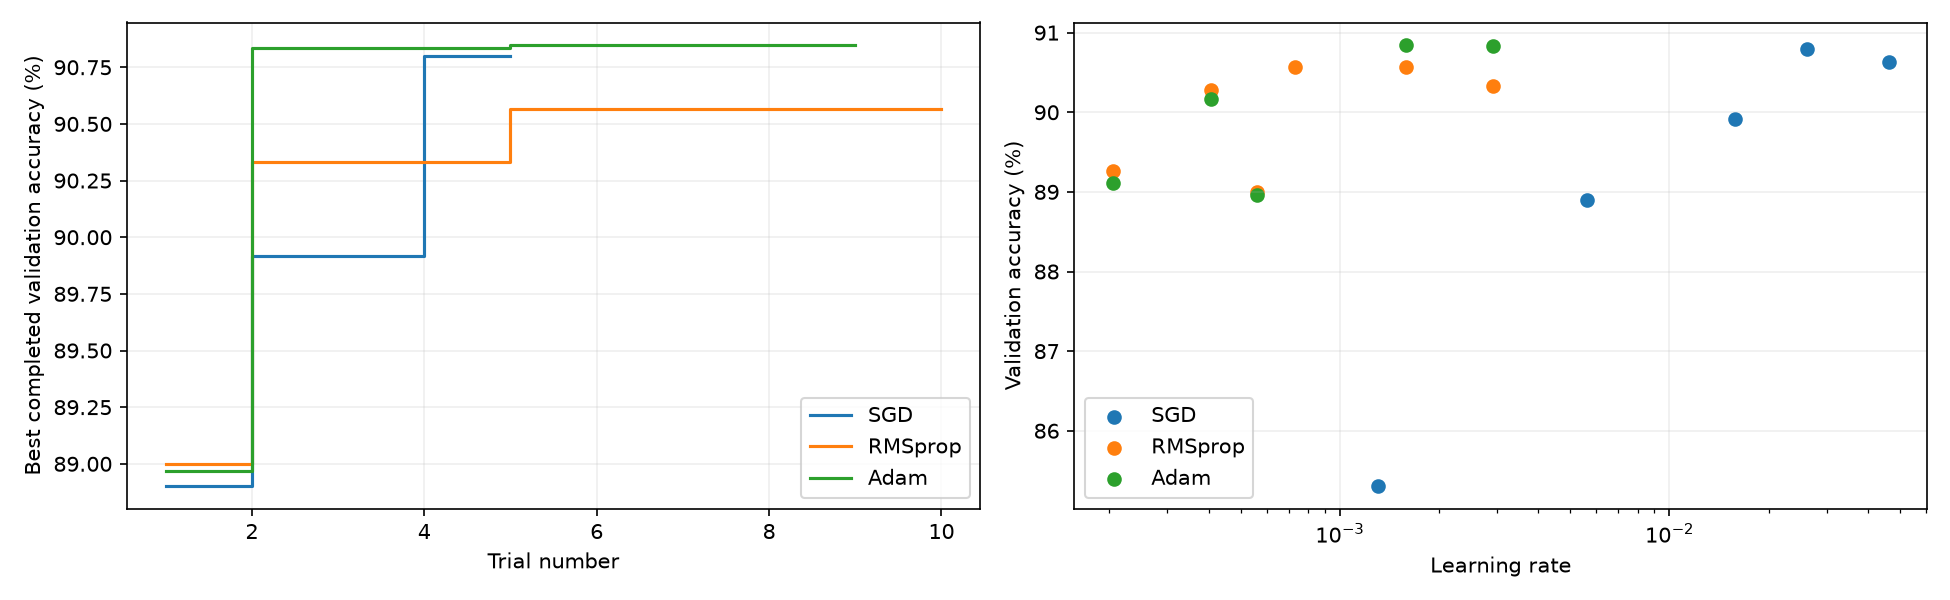

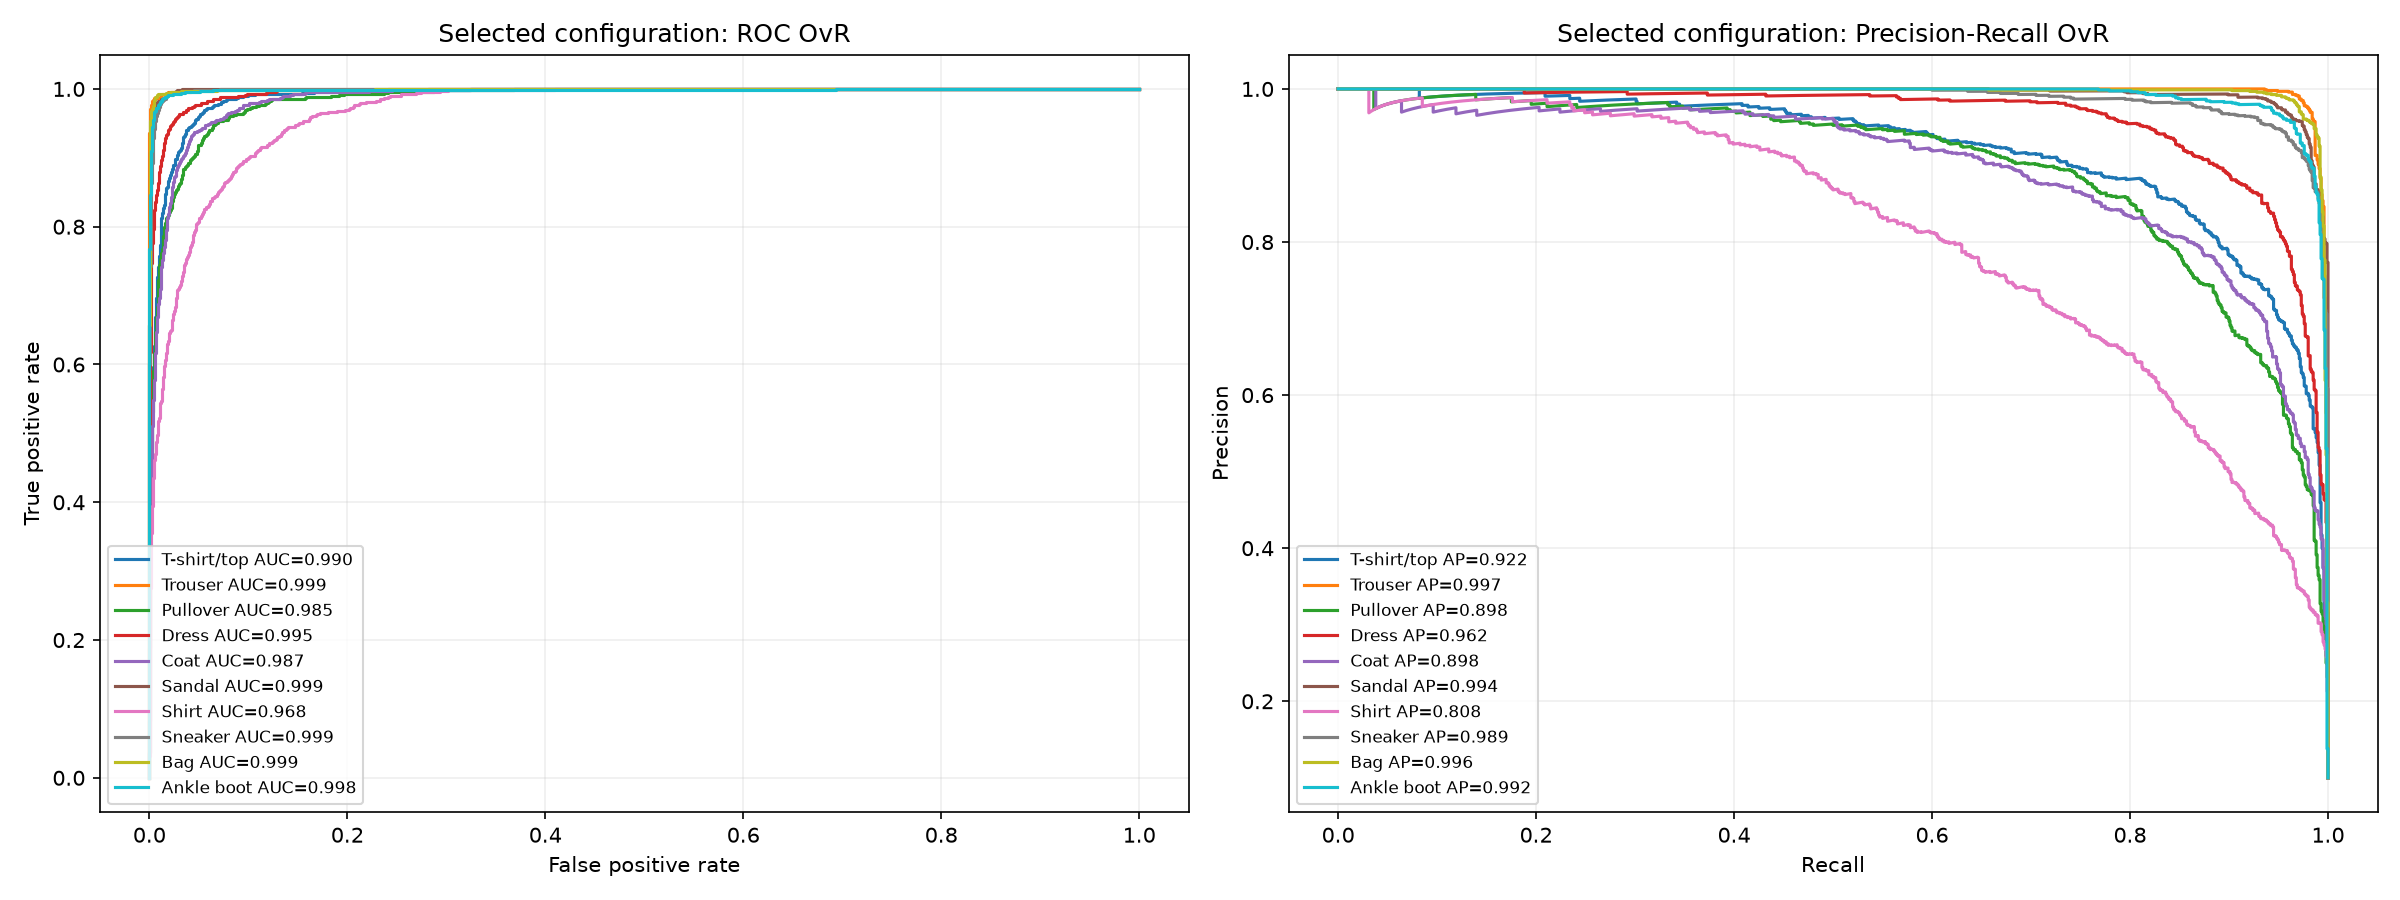

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
from src.utils.helpers import OUTPUTS_DIR
FIXED_SAVED = OUTPUTS_DIR / 'runs/20261022T130020Z_optimizer_fixed_lr_dbe789e0'
TUNING_SAVED = OUTPUTS_DIR / 'runs/20261022T130101Z_optimizer_tuning_d8986ca8'
FINAL_SAVED = OUTPUTS_DIR / 'runs/20261022T130609Z_MainMLP_0f179a92'
RESULTS_SAVED = OUTPUTS_DIR / 'runs/20261022T130646Z_optimizer_results_9db6fe2b'
display(pd.read_csv(RESULTS_SAVED / 'fixed_vs_tuned.csv'))
display(pd.read_csv(TUNING_SAVED / 'best_configs.csv')[['optimizer','lr','weight_decay','momentum','best_val_acc','completed','pruned']])
print('Test metrics of the validation-selected best configuration within tuning studies:')
print(json.loads((FINAL_SAVED / 'metrics.json').read_text()))
for image in (FIXED_SAVED / 'fixed_lr_curves.png', TUNING_SAVED / 'tuning_progress.png', RESULTS_SAVED / 'final_ovr_curves.png'):
    display(Image(filename=str(image)))


## Confusion matrices đã lưu — xem không train lại
Ảnh đầu so sánh ba model cơ sở; ảnh sau là bản refit best study optimizer. Không nhầm bản refit với MainMLP baseline. Hàng = true, cột = predicted; giá trị chuẩn hóa theo hàng. Số lượng chính xác có trong CSV artifact.

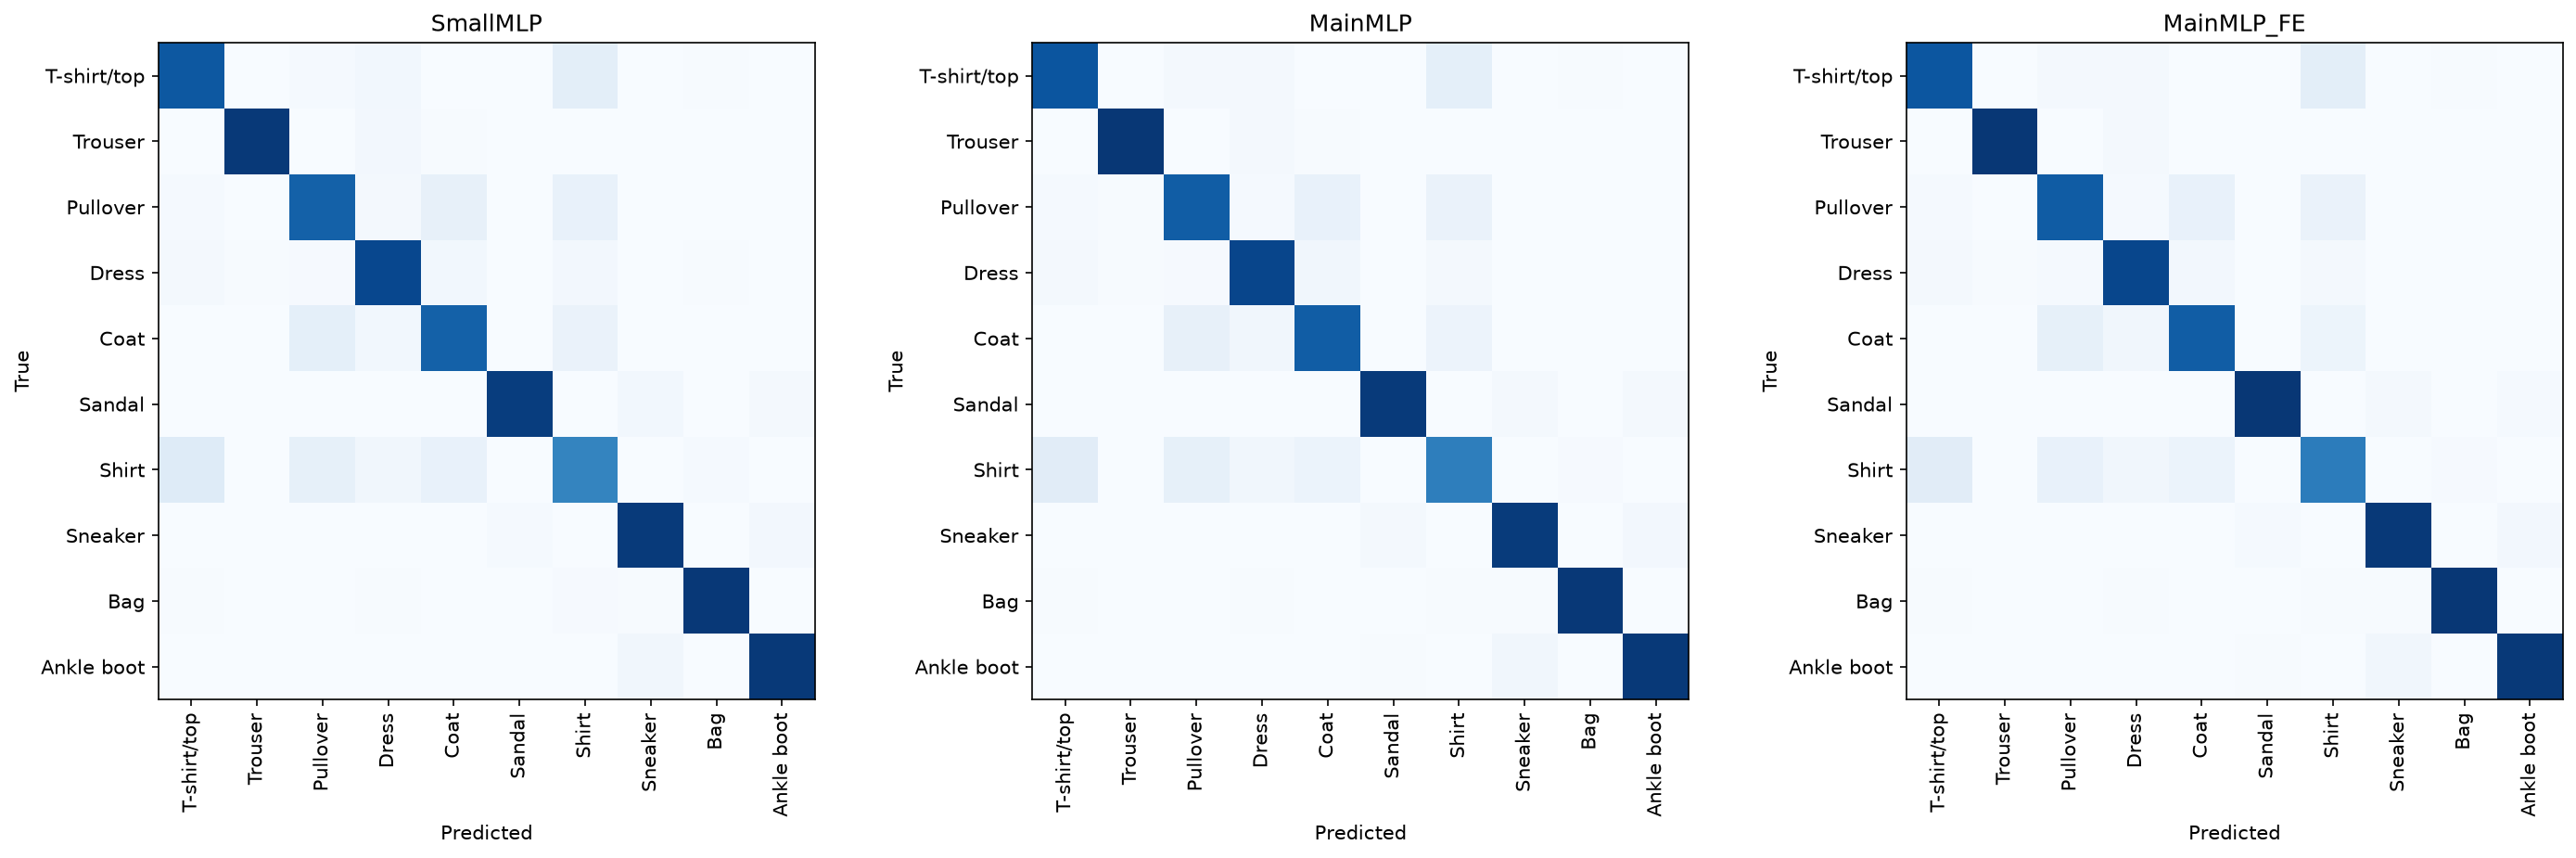

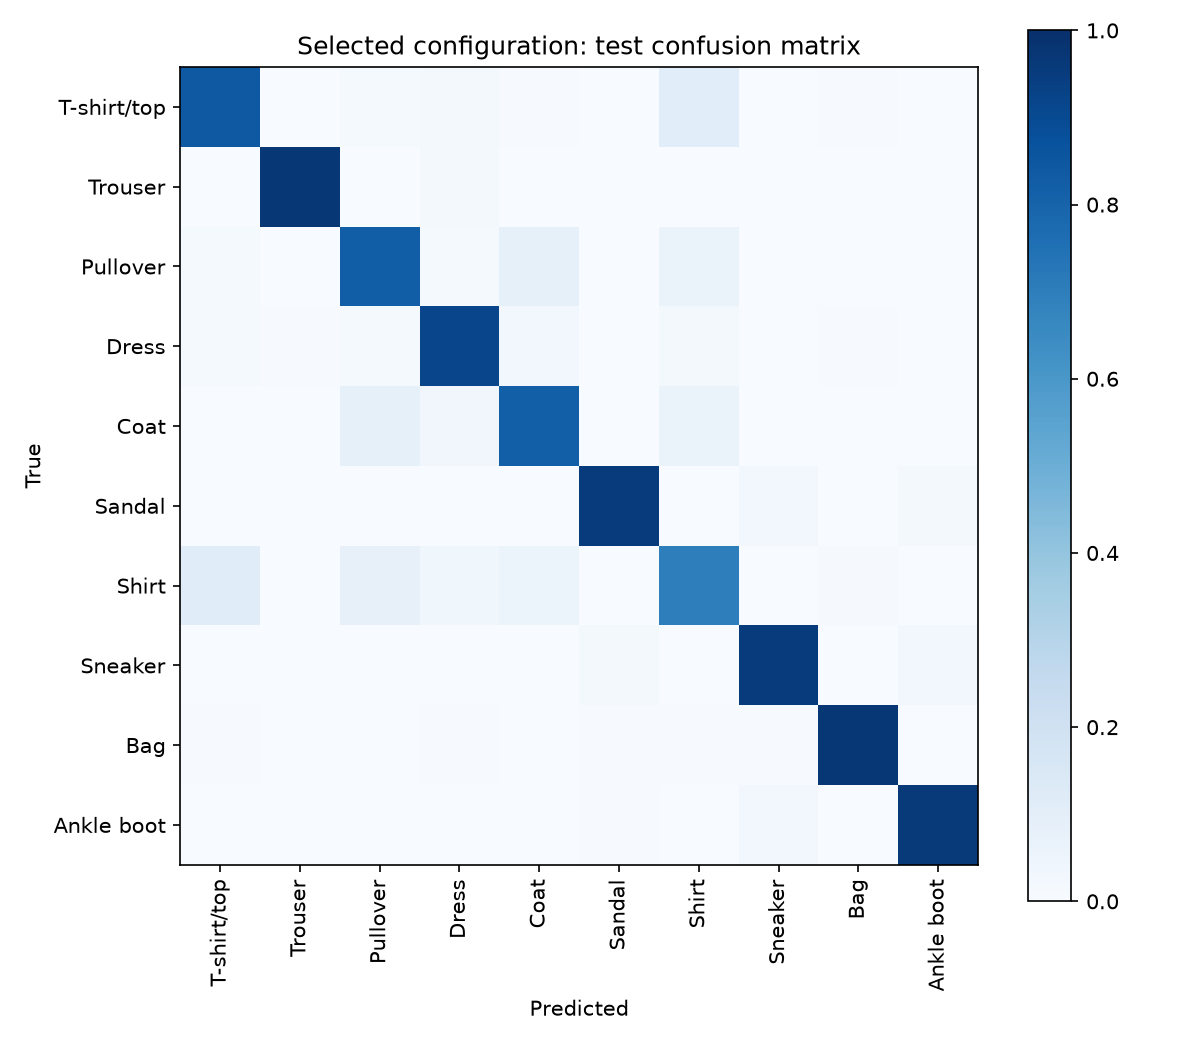

In [2]:
from src.utils.helpers import OUTPUTS_DIR
from IPython.display import display, Image
MODEL_COMPARISON_SAVED = OUTPUTS_DIR / 'runs/20261022T133548Z_comparison_6f7b5905'
TUNED_RESULTS_SAVED = OUTPUTS_DIR / 'runs/20261022T130646Z_optimizer_results_9db6fe2b'
display(Image(filename=str(MODEL_COMPARISON_SAVED / 'confusion_comparison.png')))
display(Image(filename=str(TUNED_RESULTS_SAVED / 'final_confusion_matrix.png')))
